# Ablations of AlphaFold3

In this notebook, we perform ablations of AlphaFold3 input channels, to determine the most significant contributors to antigen specicifity prediction.

In [1]:
import collections
import itertools

import IPython.display as ipy_display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from matplotlib.axes import Axes
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.metrics import auc, precision_recall_curve, roc_auc_score

In [2]:
ABLATIONS = 'no_unpaired_msas', 'no_paired_msas', 'no_templates'

possible_ablations = [
    combos for combo_size in range(1, len(ABLATIONS) + 1) for combos in itertools.combinations(ABLATIONS, combo_size)
]

## Antigen Specificity

In [3]:
def calculate_performance(pae_scores: pd.Series, labels: pd.Series) -> pd.Series:
    roc_auc = 1 - roc_auc_score(labels, pae_scores)
    roc_auc01 = 1 - roc_auc_score(labels, pae_scores, max_fpr=0.1)

    precision, recall, _ = precision_recall_curve(labels, pae_scores)
    pr_auc = 1 - auc(recall, precision)

    return pd.Series({'roc_auc': roc_auc, 'roc_auc_01': roc_auc01, 'pr_auc': pr_auc})


def format_metric_name(metric_name: str) -> str:
    return metric_name.upper().replace('_01', ' 0.1').replace('_', '-')

In [4]:
def sort_ablations(df: pd.DataFrame) -> pd.DataFrame:
    return df.sort_index(
        key=lambda idx: idx.map(
            lambda name: (
                next(i for i, entry in enumerate(possible_ablations) if name == entry)
                if isinstance(name, tuple)
                else -1
            )
        )
    )

In [5]:
sequences_1500 = pd.read_csv('../data/interim/sequences_sample_1500.csv', index_col='index')
sequences_1500['fold'] = sequences_1500['fold'].astype(str)

In [6]:
af3_confidence_scores = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')

af3_confidence_scores['top_rank'] = False
af3_confidence_scores.loc[af3_confidence_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

af3_confidence_scores['ablations'] = ''

ablation_confidence_scores = []
for ablations in possible_ablations:
    ablations_name = '_'.join(ablations)

    confidence_scores = pd.read_csv(f'../data/interim/confidence_scores_af3_af3_tcrmodel2_{ablations_name}_1500.csv')
    confidence_scores['top_rank'] = False
    confidence_scores.loc[confidence_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

    confidence_scores['ablations'] = [ablations for _ in range(len(confidence_scores))]

    ablation_confidence_scores.append(confidence_scores)

confidence_scores = pd.concat([af3_confidence_scores, *ablation_confidence_scores]).reset_index(drop=True)

In [ ]:
confidence_scores = confidence_scores.merge(sequences_1500, how='left', left_on='name', right_index=True)

### Overall

In [8]:
metric_scores = confidence_scores.groupby('ablations', dropna=False).apply(
    lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False
)
metric_scores = sort_ablations(metric_scores)

metric_scores_top_rank = (
    confidence_scores.query('top_rank')
    .groupby('ablations', dropna=False)
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
)

metric_scores_top_rank = sort_ablations(metric_scores_top_rank)

print('All')
ipy_display.display(metric_scores)

print()

print('Top Ranked')
ipy_display.display(metric_scores_top_rank)

All


,roc_auc,roc_auc_01,pr_auc
ablations,,,
,0.600320,0.502683,0.551116
"(no_unpaired_msas,)",0.588385,0.505176,0.550498
"(no_paired_msas,)",0.609911,0.504399,0.558316
"(no_templates,)",0.611813,0.506368,0.563316
"(no_unpaired_msas, no_paired_msas)",0.534675,0.505075,0.527168
"(no_unpaired_msas, no_templates)",0.607471,0.508243,0.562761
"(no_paired_msas, no_templates)",0.614985,0.505059,0.564242
"(no_unpaired_msas, no_paired_msas, no_templates)",0.469072,0.496747,0.480077



Top Ranked


,roc_auc,roc_auc_01,pr_auc
ablations,,,
,0.601319,0.504065,0.551730
"(no_unpaired_msas,)",0.587936,0.506124,0.550978
"(no_paired_msas,)",0.613895,0.505806,0.558501
"(no_templates,)",0.611984,0.505301,0.561842
"(no_unpaired_msas, no_paired_msas)",0.540357,0.499640,0.523986
"(no_unpaired_msas, no_templates)",0.607488,0.508959,0.564596
"(no_paired_msas, no_templates)",0.615680,0.505787,0.563064
"(no_unpaired_msas, no_paired_msas, no_templates)",0.475170,0.499995,0.489015


### Bootstrap

In [9]:
NUM_SAMPLES = 25
SAMPLE_SIZE = 500

names = confidence_scores['name'].unique()
rng = np.random.default_rng(123)

samples_metric_scores = []
samples_metric_scores_top_rank = []
for sample_num in range(1, NUM_SAMPLES + 1):
    sample_names = rng.choice(names, SAMPLE_SIZE)

    sample = confidence_scores[confidence_scores['name'].isin(sample_names)]

    sample_metric_scores = (
        sample.groupby('ablations', dropna=False)
        .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
        .reset_index()
    )
    sample_metric_scores['sample_num'] = sample_num

    samples_metric_scores.append(sample_metric_scores)

    sample_metric_scores_top_rank = (
        sample.query('top_rank')
        .groupby('ablations', dropna=False)
        .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
        .reset_index()
    )

    sample_metric_scores_top_rank['sample_num'] = sample_num

    samples_metric_scores_top_rank.append(sample_metric_scores_top_rank)

samples_metric_scores = pd.concat(samples_metric_scores).reset_index(drop=True)
samples_metric_scores_top_rank = pd.concat(samples_metric_scores_top_rank).reset_index(drop=True)

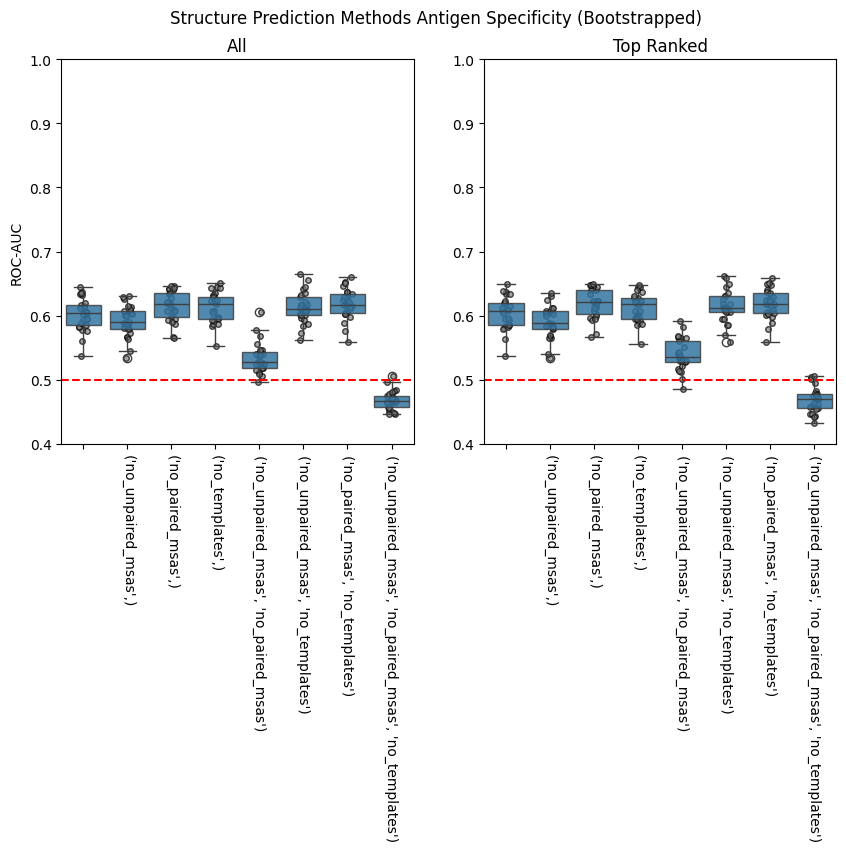

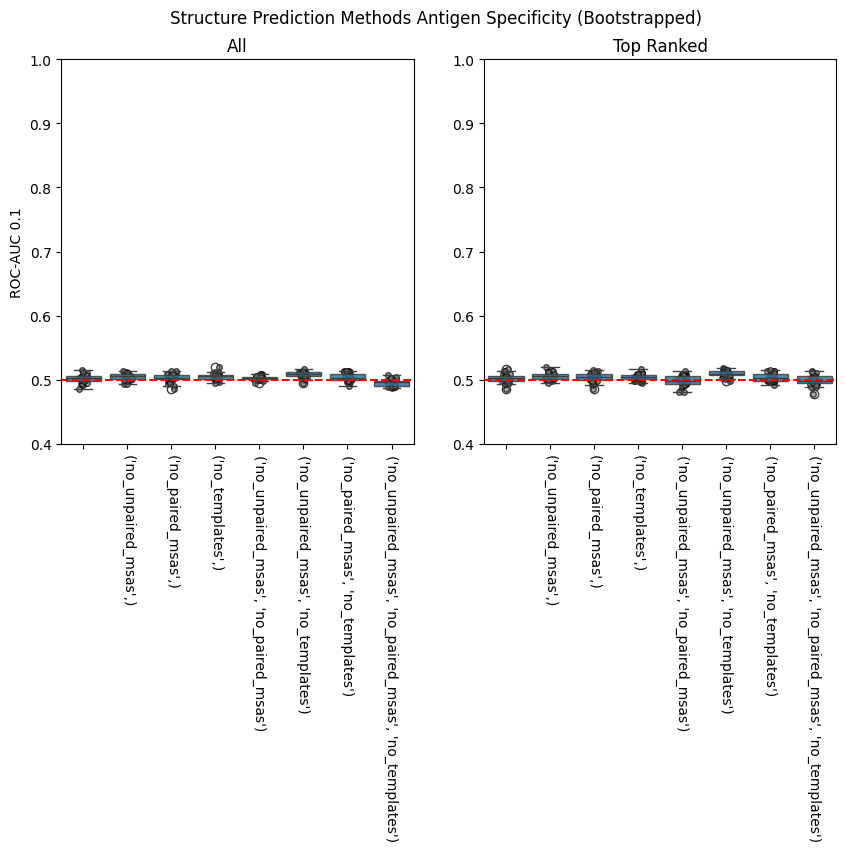

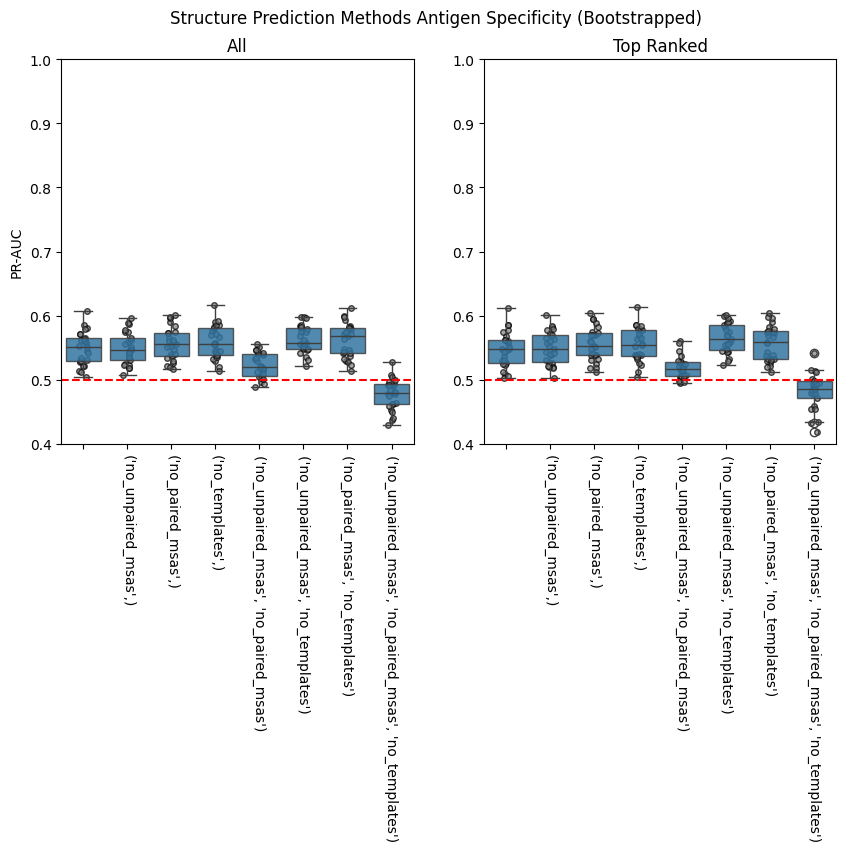

In [10]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    fig.suptitle('Structure Prediction Methods Antigen Specificity (Bootstrapped)')

    for i, (ax, title, data) in enumerate(
        zip(axes, ('All', 'Top Ranked'), (samples_metric_scores, samples_metric_scores_top_rank), strict=True)
    ):
        sns.stripplot(
            data,
            x='ablations',
            y=metric_name,
            order=['', *possible_ablations],
            color='grey',
            zorder=1,
            marker='o',
            size=4,
            edgecolor='black',
            linewidth=1,
            alpha=0.70,
            ax=ax,
        )
        sns.boxplot(
            data, x='ablations', y=metric_name, order=['', *possible_ablations], boxprops={'alpha': 0.85}, ax=ax
        )

        ax.axhline(0.5, color='r', linestyle='dashed')

        ax.set_title(title)
        ax.set_xlabel('')
        ax.set_ylim(0.4, 1.0)

        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels(ax.get_xticklabels(), rotation=270)

        if i == 0:
            ax.set_ylabel(format_metric_name(metric_name))

        else:
            ax.set_ylabel('')

    plt.savefig(f'../report/figures/alphafold3_ablations_specificity_bootstrap_{metric_name}.svg', bbox_inches='tight')
    plt.show()

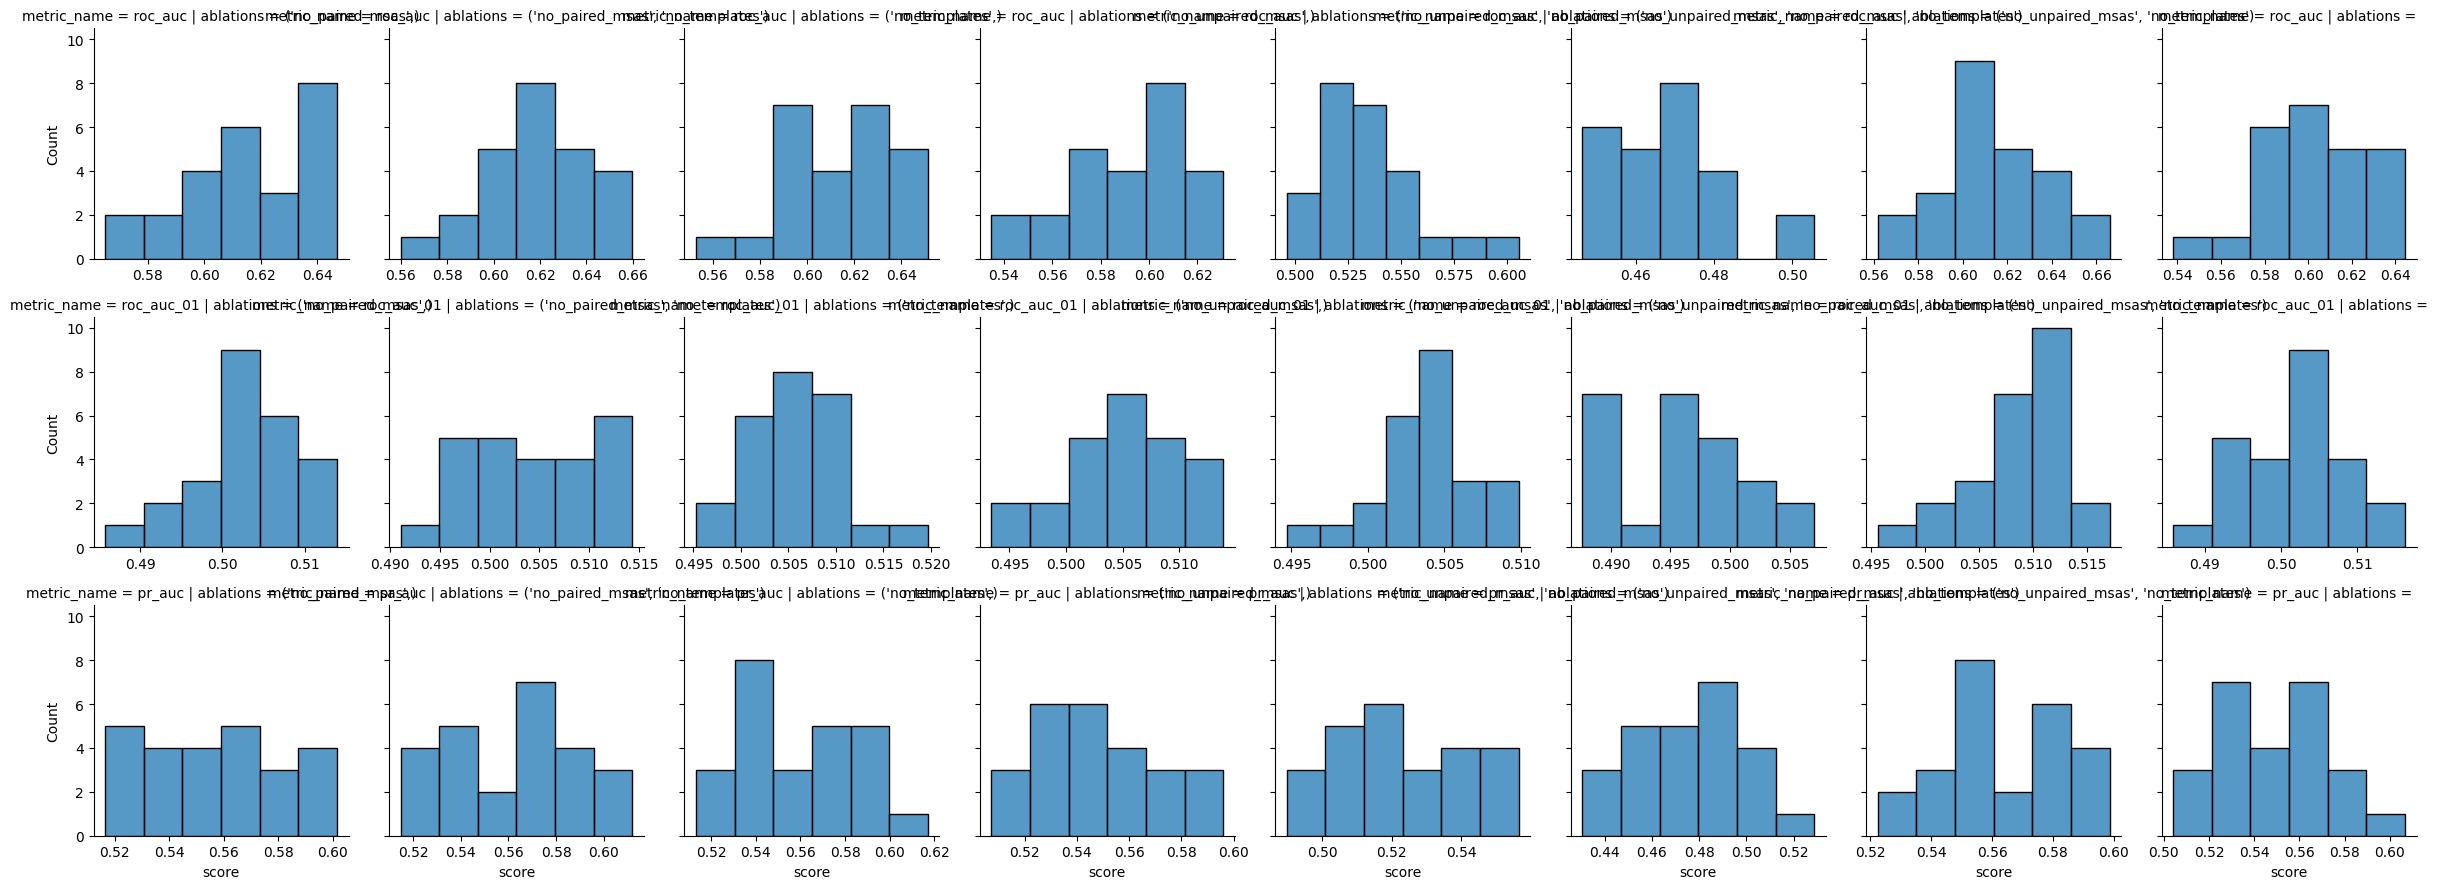

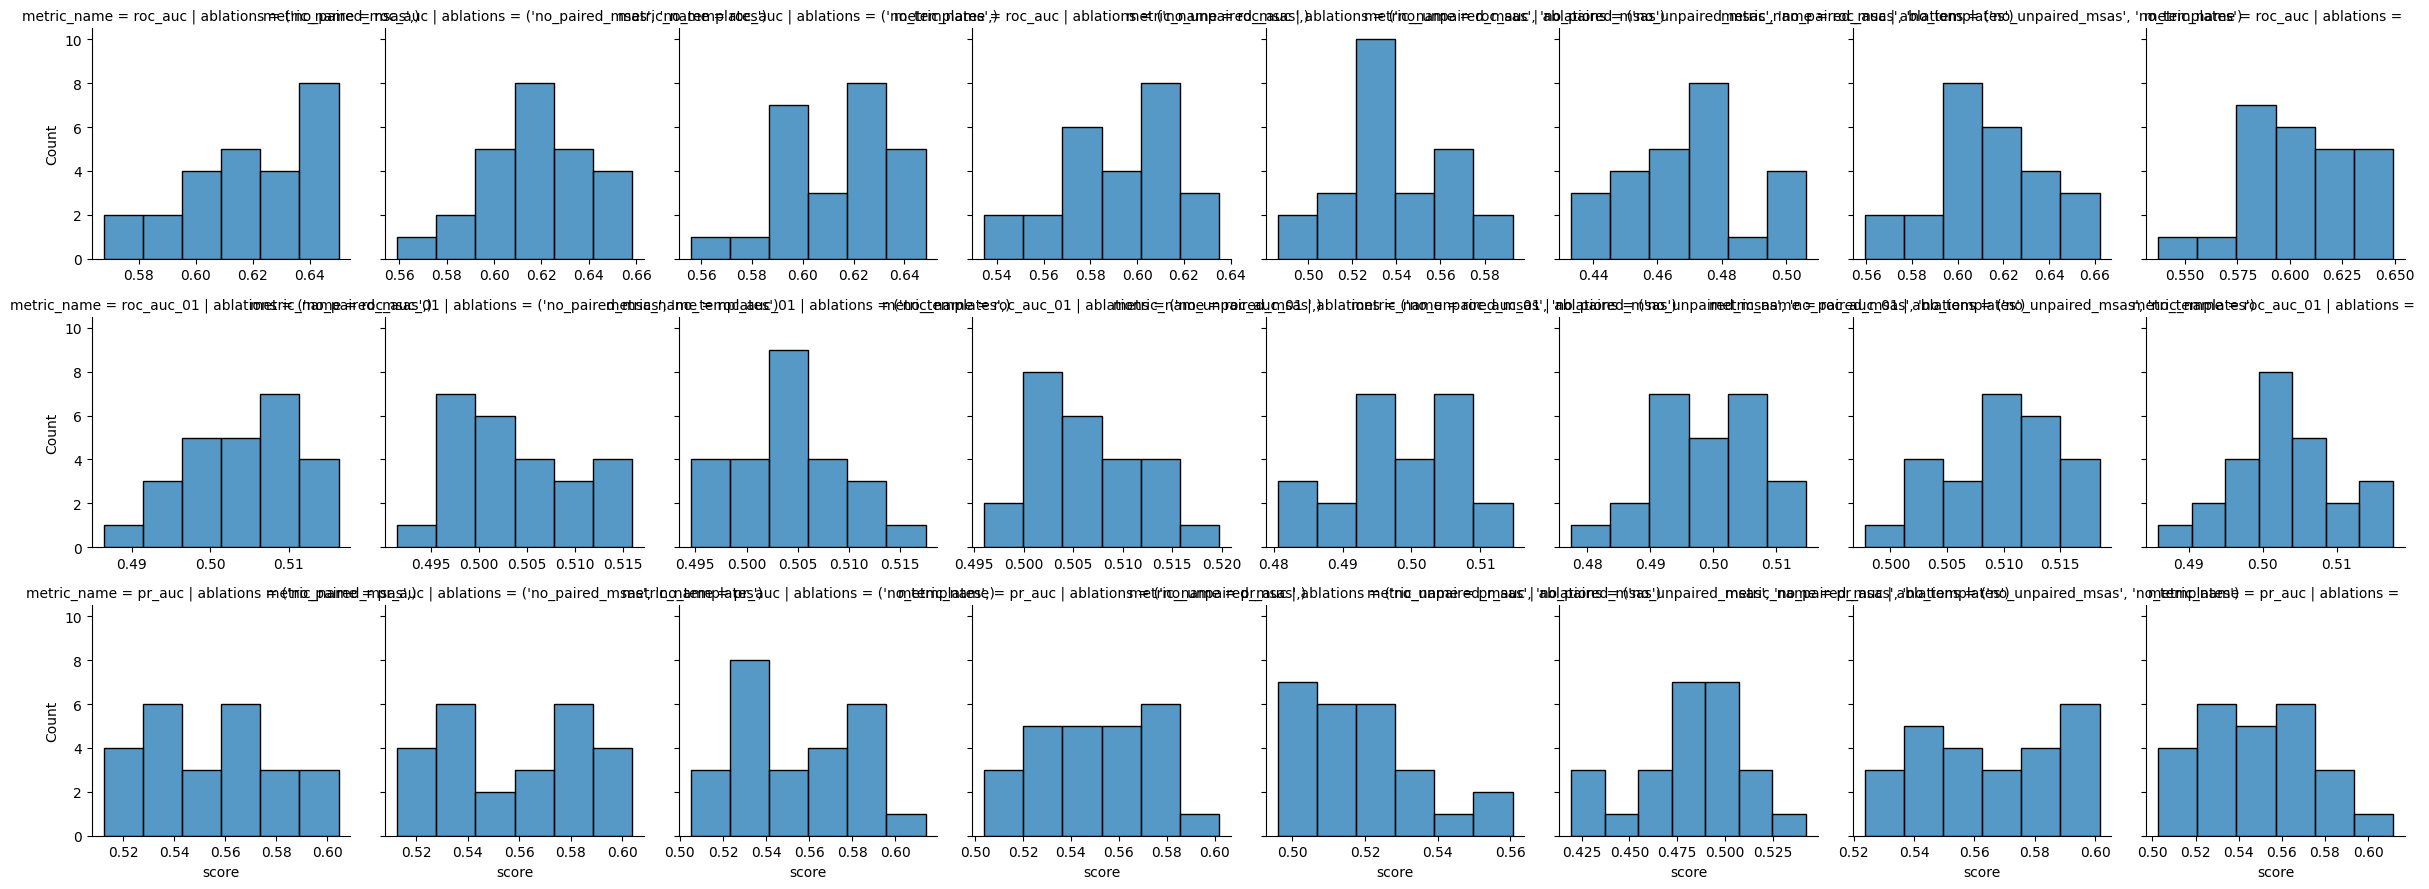

In [11]:
sns.FacetGrid(
    samples_metric_scores.melt(
        id_vars=['ablations', 'sample_num'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='ablations',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

sns.FacetGrid(
    samples_metric_scores_top_rank.melt(
        id_vars=['ablations', 'sample_num'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='ablations',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

plt.show()

In [ ]:
def statistics_normal(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.anova(data, dv=metric_name, between='ablations')

    groups = list(data.groupby('ablations', dropna=False)[metric_name])

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_ind(group1, group2, alternative='two-sided')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [13]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    print(format_metric_name(metric_name))

    for title, data in zip(('All', 'Top Ranked'), (samples_metric_scores, samples_metric_scores_top_rank), strict=True):
        print(title)
        overall, post_hoc = statistics_normal(data, metric_name)

        ipy_display.display(overall)
        ipy_display.display(post_hoc)
        print()

ROC-AUC
All


,Source,ddof1,ddof2,F,p-unc,np2
0,ablations,7,192,130.788631,1.543409e-69,0.82664


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas, no_templates)","(no_paired_msas,)",0.474729,6.371333e-01,False
1,"(no_paired_msas, no_templates)","(no_templates,)",0.794956,4.305523e-01,False
2,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas, no_templates)",26.923429,1.281234e-30,True
3,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",12.396753,1.423362e-16,True
4,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_templates)",0.778738,4.399562e-01,False
5,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",3.904254,2.947050e-04,True
6,"(no_paired_msas, no_templates)",,2.312462,2.508565e-02,False
7,"(no_paired_msas,)","(no_templates,)",0.318253,7.516733e-01,False
8,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",26.115435,5.046971e-30,True
9,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",11.849841,7.358626e-16,True



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,ablations,7,192,123.592005,1.314015e-67,0.818379


...

,Source,ddof1,ddof2,F,p-unc,np2
0,ablations,7,192,36.076202,7.020156e-32,0.568086


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas, no_templates)","(no_paired_msas,)",0.738985,4.635148e-01,False
1,"(no_paired_msas, no_templates)","(no_templates,)",0.368186,7.143530e-01,False
2,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas, no_templates)",11.729428,1.062026e-15,True
3,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",5.864362,4.037200e-07,True
4,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_templates)",-0.221839,8.253802e-01,False
5,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",1.732452,8.961485e-02,False
6,"(no_paired_msas, no_templates)",,1.734347,8.927509e-02,False
7,"(no_paired_msas,)","(no_templates,)",-0.375753,7.087563e-01,False
8,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",11.280879,4.234898e-15,True
9,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",5.210243,3.925386e-06,True



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,ablations,7,192,28.991888,4.688074e-27,0.513854


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas, no_templates)","(no_paired_msas,)",0.165098,8.695601e-01,False
1,"(no_paired_msas, no_templates)","(no_templates,)",0.298944,7.662730e-01,False
2,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas, no_templates)",9.464503,1.487290e-12,True
3,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",5.790287,5.233961e-07,True
4,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_templates)",-1.115516,2.701832e-01,False
5,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",0.936832,3.535350e-01,False
6,"(no_paired_msas, no_templates)",,1.233953,2.232283e-01,False
7,"(no_paired_msas,)","(no_templates,)",0.139232,8.898496e-01,False
8,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",9.563128,1.070811e-12,True
9,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",5.827912,4.587577e-07,True


### By Fold

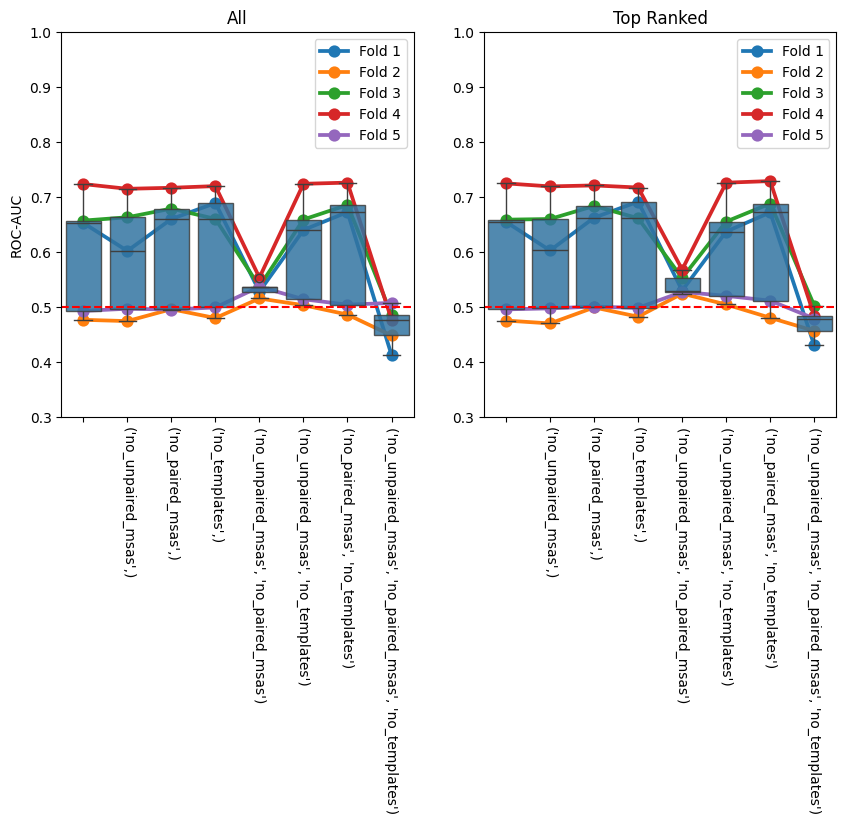

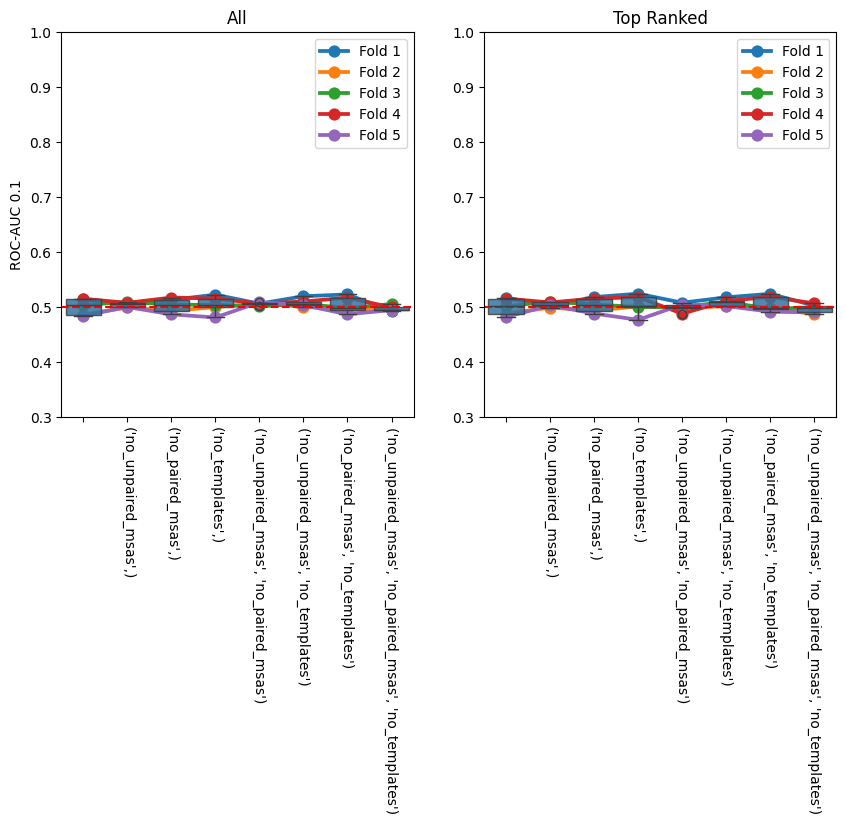

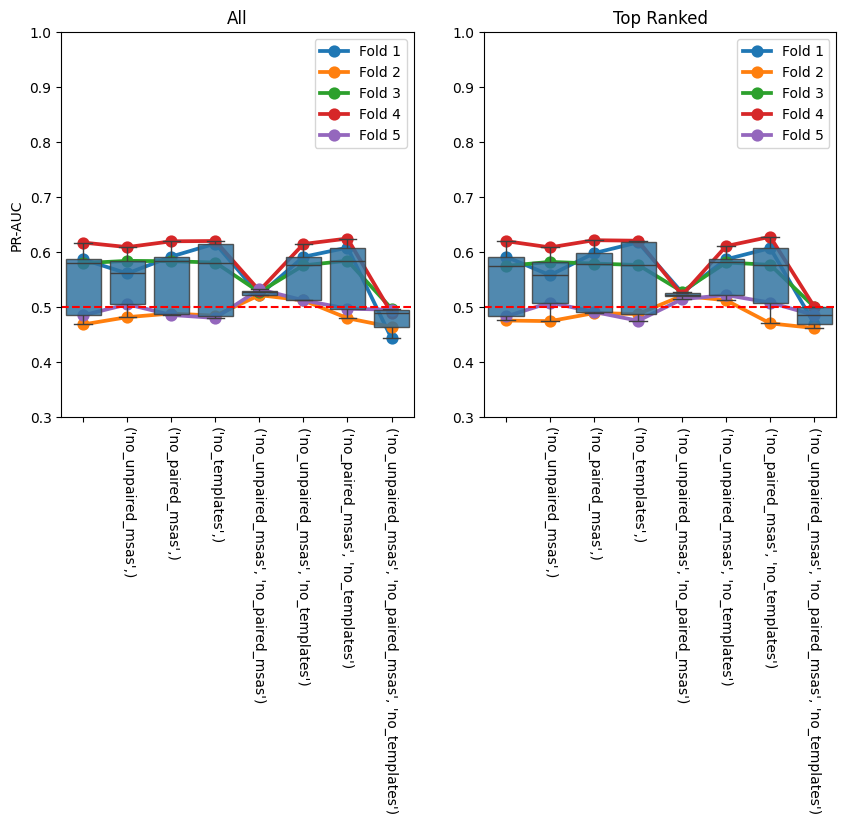

In [14]:
roc_aucs_by_fold = (
    confidence_scores.groupby(['ablations', 'fold'], dropna=False)
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
    .reset_index()
)

roc_aucs_by_fold_top_rank = (
    confidence_scores.query('top_rank')
    .groupby(['ablations', 'fold'], dropna=False)
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
    .reset_index()
)


for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for i, (ax, title, data) in enumerate(
        zip(axes, ('All', 'Top Ranked'), (roc_aucs_by_fold, roc_aucs_by_fold_top_rank), strict=True)
    ):
        sns.pointplot(data, x='ablations', y=metric_name, order=['', *possible_ablations], hue='fold', ax=ax)
        sns.boxplot(
            data, x='ablations', y=metric_name, order=['', *possible_ablations], boxprops={'alpha': 0.85}, ax=ax
        )

        ax.axhline(0.5, color='r', linestyle='dashed')

        ax.set_title(title)
        ax.set_xlabel('')
        ax.set_ylim(0.3, 1.0)

        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels(ax.get_xticklabels(), rotation=270)

        handles, labels = ax.get_legend_handles_labels()
        new_labels = [f'Fold {label}' for label in labels]
        ax.legend(handles, new_labels)

        if i == 0:
            ax.set_ylabel(format_metric_name(metric_name))

        else:
            ax.set_ylabel('')

    plt.savefig(f'../report/figures/alphafold3_ablations_specificity_fold_{metric_name}.svg', bbox_inches='tight')
    plt.show()

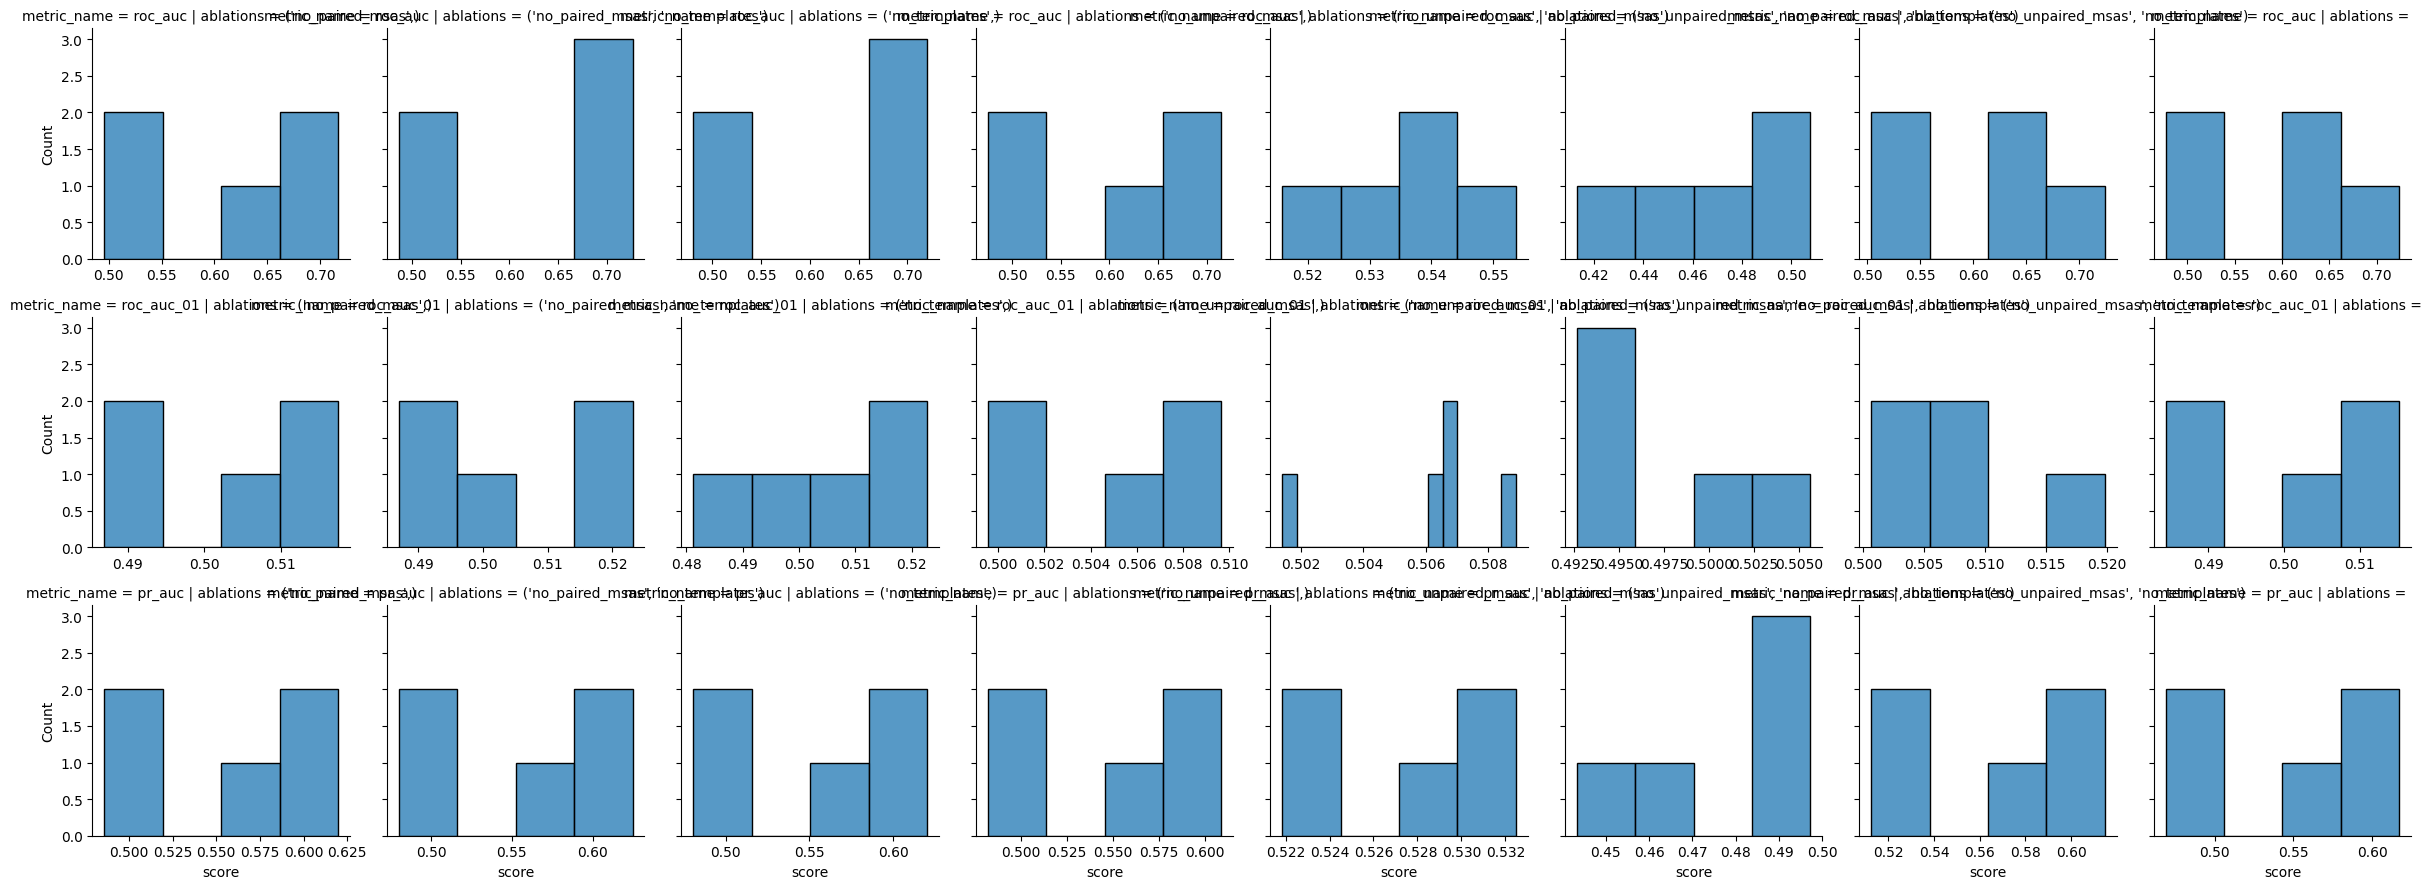

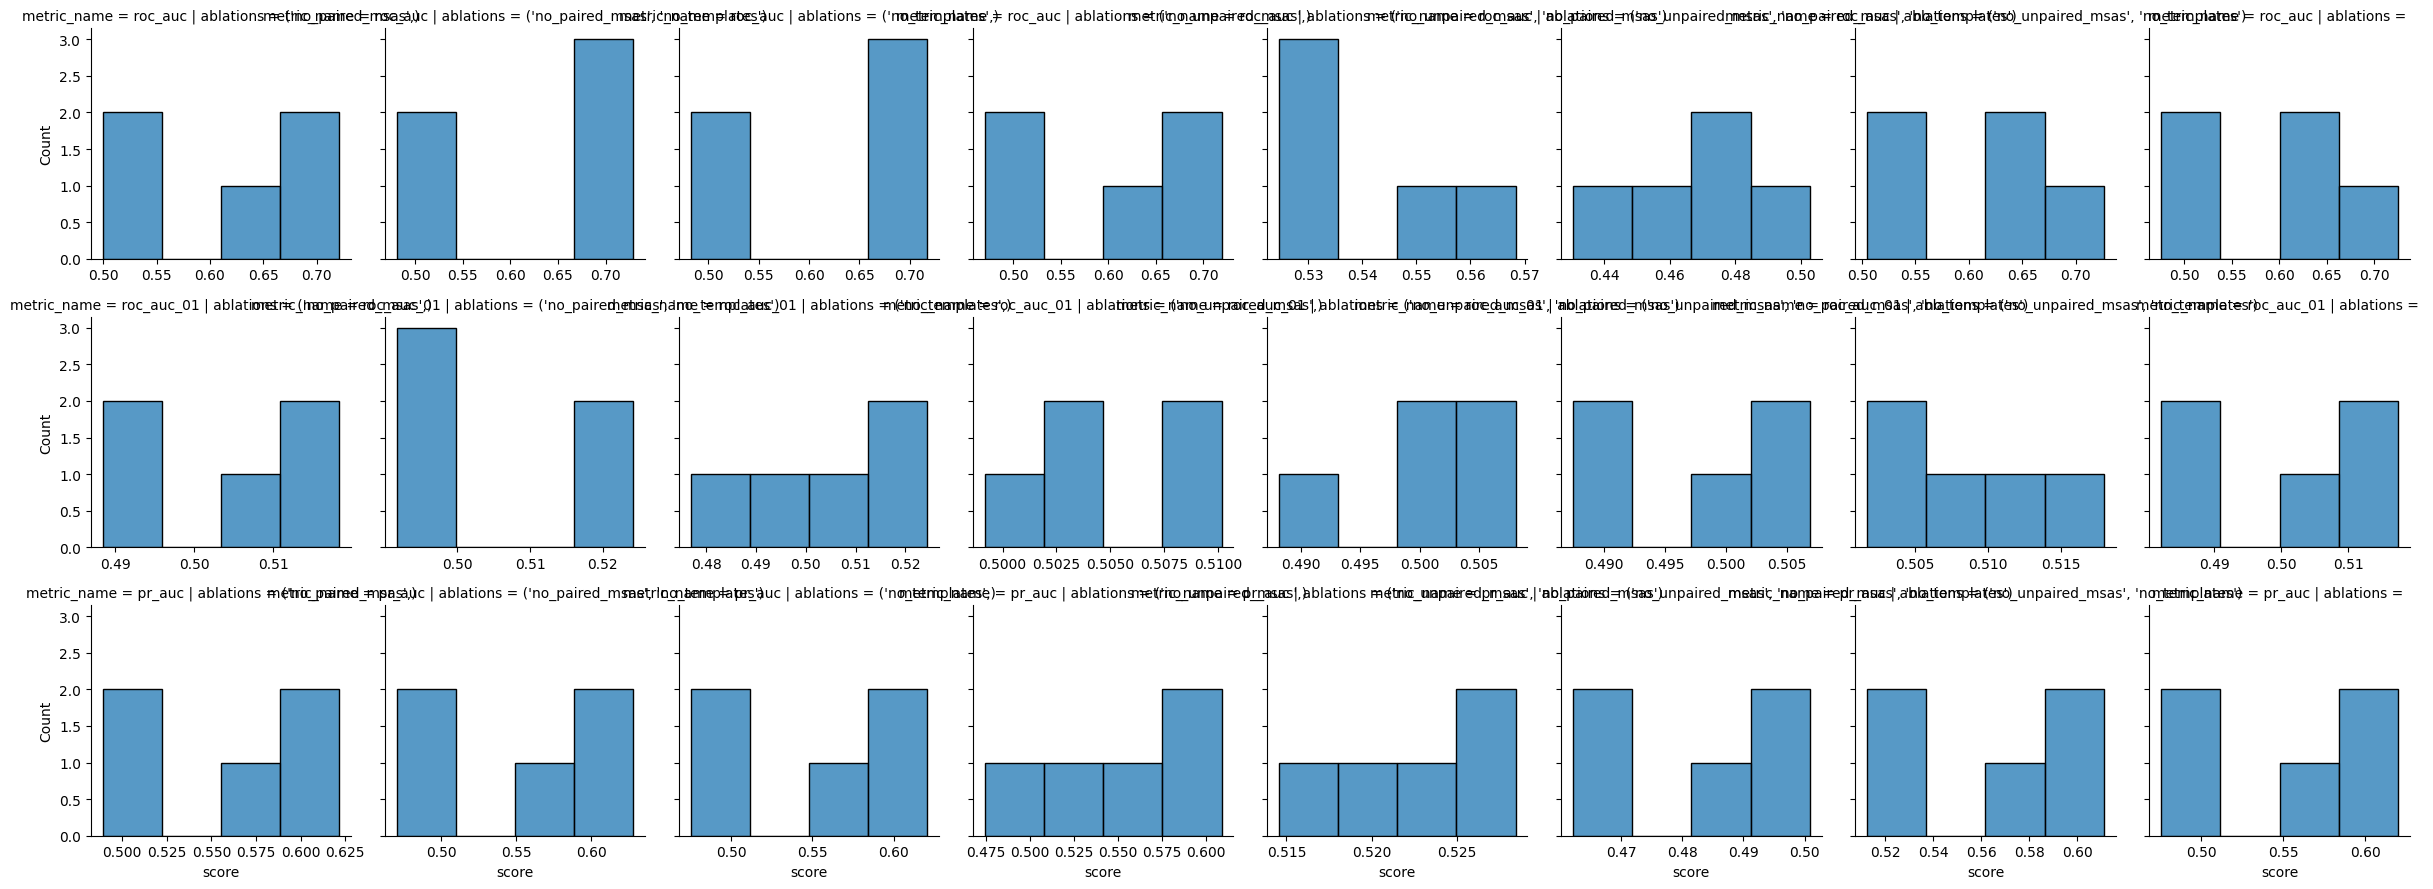

In [15]:
sns.FacetGrid(
    roc_aucs_by_fold.melt(
        id_vars=['ablations', 'fold'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='ablations',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

sns.FacetGrid(
    roc_aucs_by_fold_top_rank.melt(
        id_vars=['ablations', 'fold'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='ablations',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

plt.show()

In [ ]:
def statistics_non_parametric(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.friedman(data, dv=metric_name, within='ablations', subject='fold', method='f')

    groups = list(data.set_index('fold').groupby('ablations')[metric_name])
    groups = [(group_name, group.sort_index()) for group_name, group in groups]

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.wilcoxon(group1, group2, alternative='greater')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [ ]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    print(format_metric_name(metric_name))

    for title, data in zip(('All', 'Top Ranked'), (roc_aucs_by_fold, roc_aucs_by_fold_top_rank), strict=True):
        print(title)
        overall, post_hoc = statistics_non_parametric(data, metric_name)

        ipy_display.display(overall)
        ipy_display.display(post_hoc)

        print()

    print()

ROC-AUC
All


,Source,W,ddof1,ddof2,F,p-unc
Friedman,ablations,0.36,6.6,26.4,2.25,0.064774


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas, no_templates)","(no_paired_msas,)",11.0,0.21875,False
1,"(no_paired_msas, no_templates)","(no_templates,)",11.0,0.21875,False
2,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas, no_templates)",14.0,0.06250,False
3,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",12.0,0.15625,False
4,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_templates)",10.0,0.31250,False
5,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",15.0,0.03125,False
6,"(no_paired_msas, no_templates)",,15.0,0.03125,False
7,"(no_paired_msas,)","(no_templates,)",7.0,0.59375,False
8,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",14.0,0.06250,False
9,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",12.0,0.15625,False



Top Ranked


,Source,W,ddof1,ddof2,F,p-unc
Friedman,ablations,0.512381,6.6,26.4,4.203125,0.003526


...

,Source,W,ddof1,ddof2,F,p-unc
Friedman,ablations,0.340952,6.6,26.4,2.069364,0.086298


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas, no_templates)","(no_paired_msas,)",12.0,0.15625,False
1,"(no_paired_msas, no_templates)","(no_templates,)",8.0,0.50000,False
2,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas, no_templates)",15.0,0.03125,False
3,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",12.0,0.15625,False
4,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_templates)",7.0,0.59375,False
5,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",10.0,0.31250,False
6,"(no_paired_msas, no_templates)",,15.0,0.03125,False
7,"(no_paired_msas,)","(no_templates,)",9.0,0.40625,False
8,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",14.0,0.06250,False
9,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",12.0,0.15625,False



Top Ranked


,Source,W,ddof1,ddof2,F,p-unc
Friedman,ablations,0.358095,6.6,26.4,2.231454,0.066706


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas, no_templates)","(no_paired_msas,)",9.0,0.40625,False
1,"(no_paired_msas, no_templates)","(no_templates,)",8.0,0.50000,False
2,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas, no_templates)",15.0,0.03125,False
3,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",11.0,0.21875,False
4,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_templates)",7.0,0.59375,False
5,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",9.0,0.40625,False
6,"(no_paired_msas, no_templates)",,13.0,0.09375,False
7,"(no_paired_msas,)","(no_templates,)",10.0,0.31250,False
8,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",15.0,0.03125,False
9,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",12.0,0.15625,False


## Structure Quality

In [ ]:
alphafold3_dockq = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_dockq_benchmark.csv')
alphafold3_benchmark_confidences = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_benchmark.csv')

alphafold3_benchmark_confidences['top_rank'] = False
alphafold3_benchmark_confidences.loc[
    alphafold3_benchmark_confidences.groupby('name')['ranking_score'].idxmax(), 'top_rank'
] = True

alphafold3_dockq = alphafold3_dockq.merge(alphafold3_benchmark_confidences, how='outer', on=['name', 'seed', 'sample'])
alphafold3_dockq = alphafold3_dockq.fillna(0.0)

alphafold3_dockq['ablations'] = ''

In [19]:
ablation_dockqs = []
for ablations in possible_ablations:
    ablations_name = '_'.join(ablations)

    dockq = pd.read_csv(f'../data/processed/predicted_af3_af3_tcrmodel2_{ablations_name}_dockq_benchmark.csv')
    confidences = pd.read_csv(f'../data/interim/confidence_scores_af3_af3_tcrmodel2_{ablations_name}_benchmark.csv')

    confidences['top_rank'] = False
    confidences.loc[confidences.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

    dockq = dockq.merge(confidences, how='outer', on=['name', 'seed', 'sample'])
    dockq = dockq.fillna(0.0)

    dockq['ablations'] = [ablations for _ in range(len(dockq))]

    ablation_dockqs.append(dockq)

ablation_dockqs = pd.concat(ablation_dockqs).reset_index(drop=True)

In [20]:
dockq_scores = pd.concat([alphafold3_dockq, ablation_dockqs]).reset_index(drop=True)

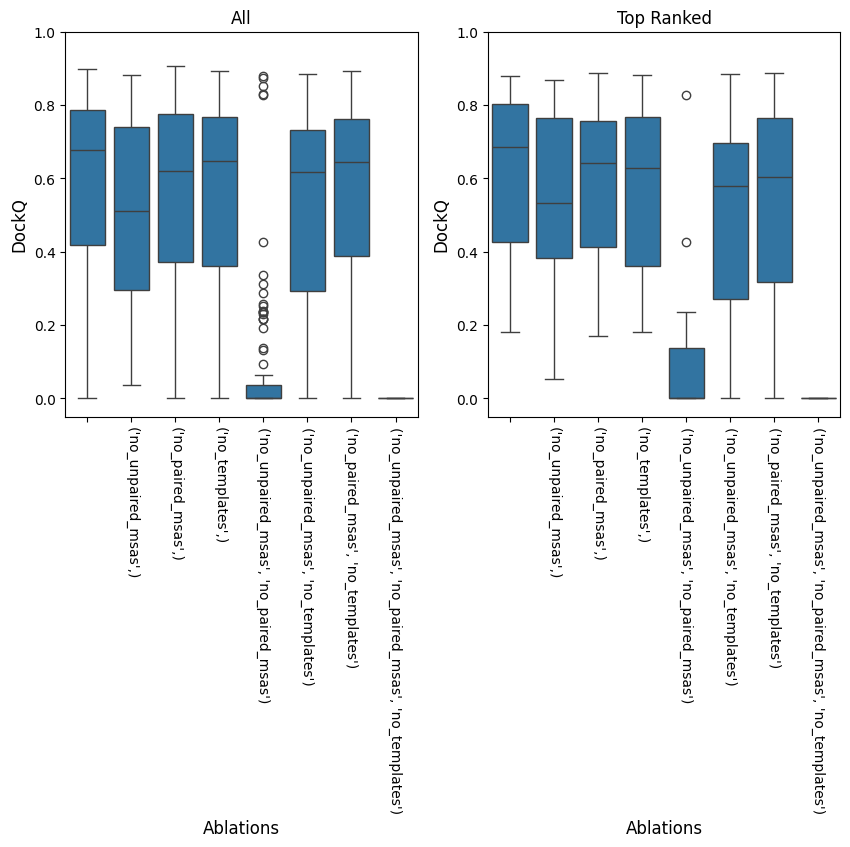

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, title, data in zip(axes, ('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    ax.set_title(title)
    sns.boxplot(data, x='ablations', y='DockQ', ax=ax)

    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(ax.get_xticklabels(), rotation=270)

    ax.set_xlabel(ax.get_xlabel().title(), fontsize=12)
    ax.set_ylabel(ax.get_ylabel(), fontsize=12)

    ax.set_ylim(-0.05, 1.0)

plt.savefig('../report/figures/alphafold3_ablations_dockq_boxplot.svg', bbox_inches='tight')
plt.show()

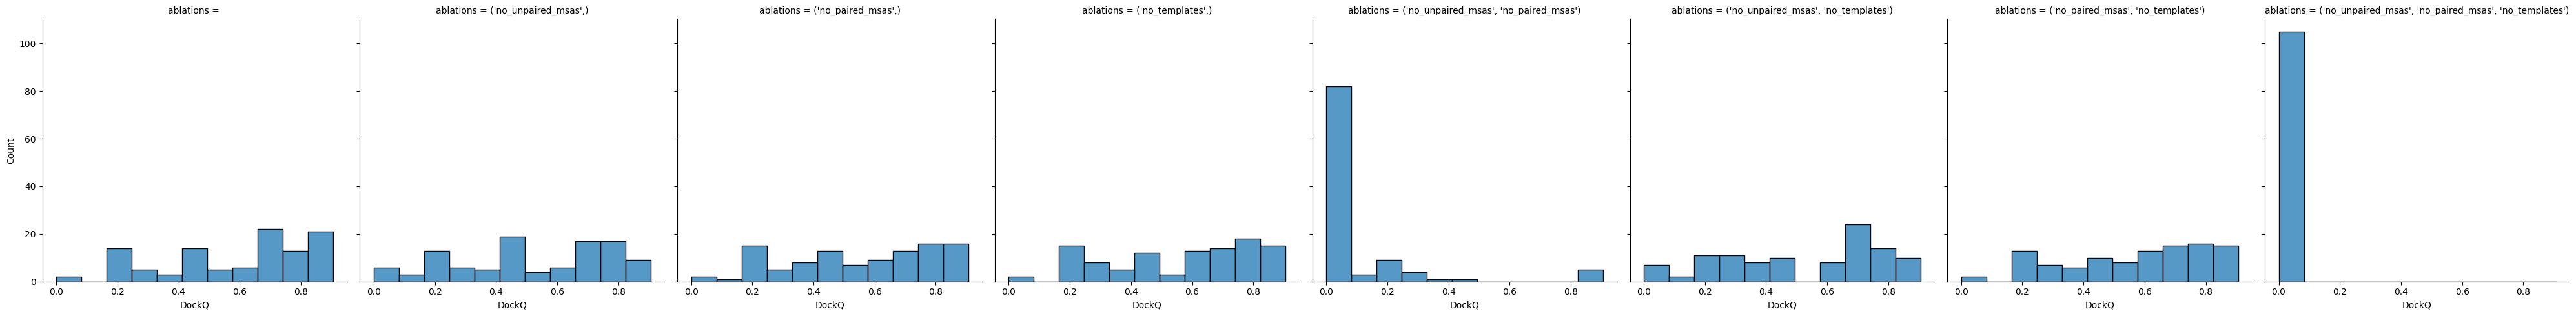

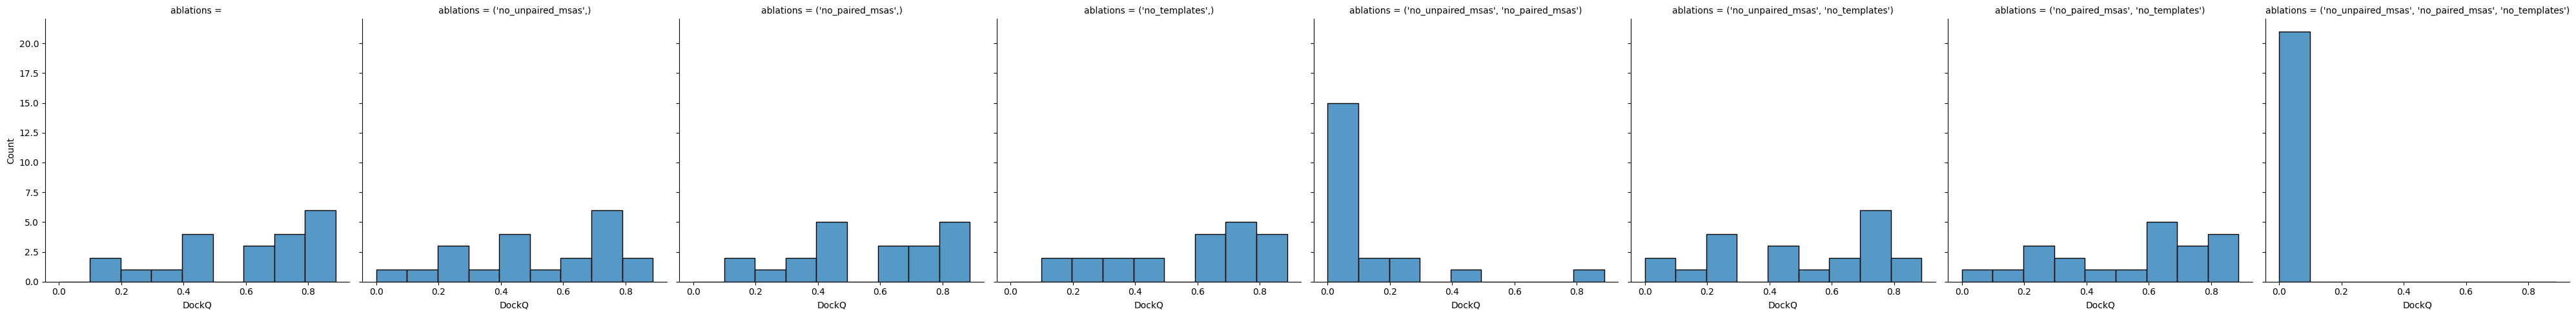

In [22]:
sns.displot(dockq_scores, col='ablations', x='DockQ', kind='hist')
sns.displot(dockq_scores.query('top_rank'), col='ablations', x='DockQ', kind='hist')

plt.show()

In [23]:
for title, data in zip(('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    print(title)

    ipy_display.display(pg.anova(data, dv='DockQ', between='ablations'))

    groups = list(data.groupby('ablations')['DockQ'])

    significance_level = 0.05 / len(groups)

    results = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_ind(group1, group2, alternative='two-sided')

        results['group1'].append(group1_name)
        results['group2'].append(group2_name)
        results['stat'].append(stat)
        results['p_val'].append(p_val)
        results['signficant'].append(p_val < significance_level)

    ipy_display.display(pd.DataFrame(results))
    print()

All


,Source,ddof1,ddof2,F,p-unc,np2
0,ablations,7,832,122.298702,2.955921e-123,0.507136


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas,)","(no_paired_msas, no_templates)",-0.222267,8.243239e-01,False
1,"(no_paired_msas,)","(no_templates,)",-0.131362,8.956161e-01,False
2,"(no_paired_msas,)","(no_unpaired_msas,)",1.293007,1.974429e-01,False
3,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",15.635007,5.932432e-37,True
4,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",23.598985,9.851857e-61,True
5,"(no_paired_msas,)","(no_unpaired_msas, no_templates)",1.217333,2.248569e-01,False
6,"(no_paired_msas,)",,-0.896939,3.707885e-01,False
7,"(no_paired_msas, no_templates)","(no_templates,)",0.088731,9.293812e-01,False
8,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",1.543412,1.242509e-01,False
9,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",16.318211,4.332296e-39,True



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,ablations,7,160,22.939939,2.382961e-21,0.500904


,group1,group2,stat,p_val,signficant
0,"(no_paired_msas,)","(no_paired_msas, no_templates)",0.220967,8.262424e-01,False
1,"(no_paired_msas,)","(no_templates,)",-0.193467,8.475724e-01,False
2,"(no_paired_msas,)","(no_unpaired_msas,)",0.399873,6.913776e-01,False
3,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas)",6.820150,3.341004e-08,True
4,"(no_paired_msas,)","(no_unpaired_msas, no_paired_msas, no_templates)",10.887244,1.573142e-13,True
5,"(no_paired_msas,)","(no_unpaired_msas, no_templates)",0.710873,4.812880e-01,False
6,"(no_paired_msas,)",,-0.552588,5.836203e-01,False
7,"(no_paired_msas, no_templates)","(no_templates,)",-0.403825,6.884922e-01,False
8,"(no_paired_msas, no_templates)","(no_unpaired_msas,)",0.163087,8.712712e-01,False
9,"(no_paired_msas, no_templates)","(no_unpaired_msas, no_paired_msas)",6.197458,2.494048e-07,True


In [24]:
CAPRI_ACCEPTABLE_CUTOFF = 0.23
CAPRI_MEDIUM_CUTOFF = 0.49
CAPRI_HIGH_CUTOFF = 0.80


def get_capri_classification(dockq: float) -> str:
    if dockq < CAPRI_ACCEPTABLE_CUTOFF:
        return 'Incorrect'

    if CAPRI_ACCEPTABLE_CUTOFF <= dockq < CAPRI_MEDIUM_CUTOFF:
        return 'Acceptable'

    if CAPRI_MEDIUM_CUTOFF <= dockq < CAPRI_HIGH_CUTOFF:
        return 'Medium'

    return 'High'

In [25]:
dockq_scores['capri_classification'] = dockq_scores['DockQ'].map(get_capri_classification)

In [26]:
def plot_capri_classification(dockq_scores: pd.DataFrame, ax: Axes | None = None) -> Axes:
    order = ['High', 'Medium', 'Acceptable', 'Incorrect']
    colours = {
        'High': '#7f0d0d',
        'Medium': '#ff1a1a',
        'Acceptable': '#ff7f7f',
        'Incorrect': '#e6e6e6',
    }

    capri_classification = dockq_scores.groupby('ablations')['capri_classification'].value_counts(normalize=True) * 100
    capri_classification.name = 'percent'
    capri_classification = capri_classification.reset_index()
    capri_classification = capri_classification.pivot_table(
        index='ablations', columns='capri_classification', values='percent'
    )
    capri_classification = capri_classification.reindex(columns=order, fill_value=0)
    capri_classification = capri_classification.sort_index(
        key=lambda idx: idx.map(
            lambda name: (
                next(i for i, entry in enumerate(possible_ablations) if name == entry)
                if isinstance(name, tuple)
                else -1
            )
        )
    )

    plot_ax = capri_classification.plot(
        kind='bar',
        stacked=True,
        color=[colours[col_name] for col_name in order],
        width=0.8,
        edgecolor='none',
        legend=False,
        ax=ax,
    )

    plot_ax.set_ylim(0, 100)
    plot_ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    plot_ax.set_ylabel('Success rate', fontsize=12)
    plot_ax.set_yticks([0, 25, 50, 75, 100])
    plot_ax.set_xlabel('')

    return plot_ax

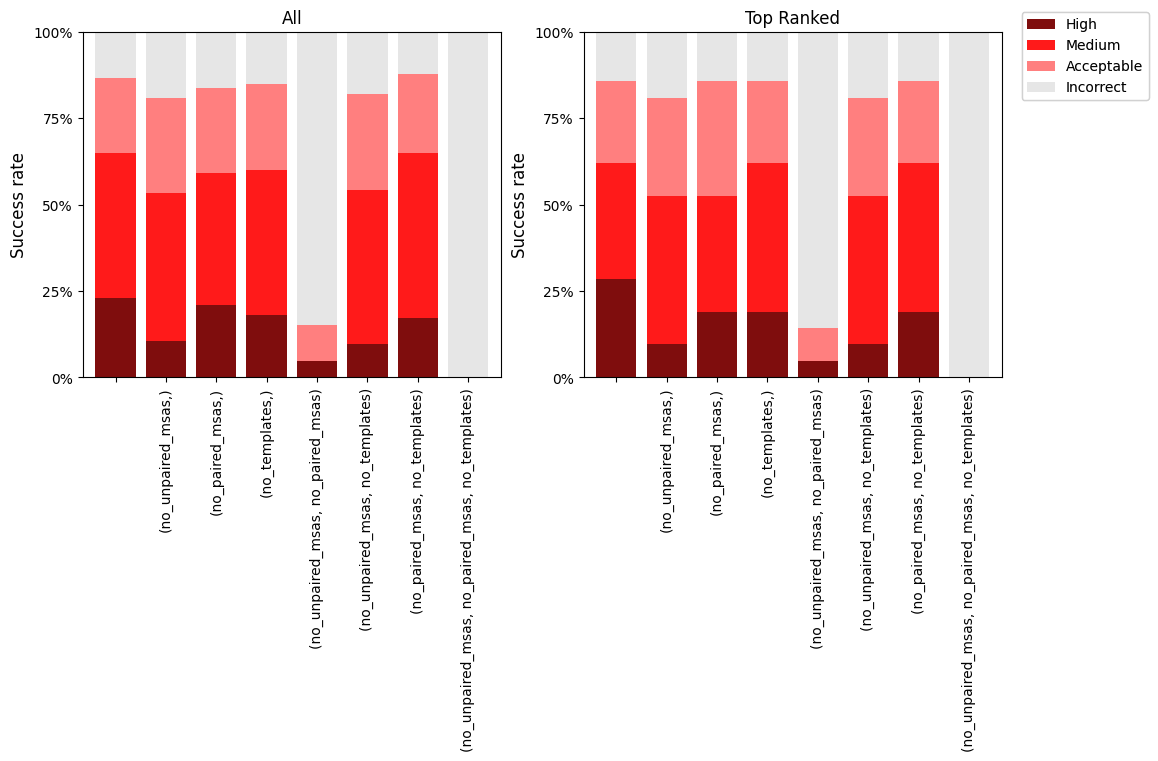

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 7.5), constrained_layout=True)

for ax, title, data in zip(axes, ('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    ax.set_title(title)

    plot_capri_classification(data, ax=ax)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, bbox_to_anchor=(1.15, 1))

plt.savefig('../report/figures/alphafold3_ablations_dockq_capri.svg', bbox_inches='tight')
plt.show()